# 03 · Hold-out results, error analysis, explainability and uncertainty

Notebook 02 picked the model using cross-validation on the 80 % training split. Here the **sealed 20 % hold-out is opened exactly once** to answer four questions an engineer (or a buyer) should ask of any price model:

1. **How good is it, really?** The unbiased hold-out number, with a confidence interval.
2. **Where does it fail?** Residuals by segment and the worst misses.
3. **Why does it predict what it predicts?** Permutation importance and SHAP.
4. **How sure is each prediction?** Prediction intervals, and a check of their *empirical* coverage.

In [1]:
import os
os.environ["PYTHONWARNINGS"] = "ignore"
import json, time, warnings
warnings.filterwarnings("ignore")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import shap
from IPython.display import Markdown, display
from matplotlib.colors import LinearSegmentedColormap
from scipy import stats
from sklearn.inspection import permutation_importance
from sklearn.metrics import make_scorer

from housing import config, data, models, tune
from housing import plotting as P
from housing.evaluation import bootstrap_ci, regression_metrics, repeated_cv, rmsle
from housing.interval import (ConformalQuantileInterval, ConformalResidualInterval, abs_residual_interval,
                              coverage_report, sale_group, wilson_interval)
from housing.models import _lgbm, _pipe, build, log_target
from housing.train import FINAL_MODEL, INTERVAL_ALPHA, train_and_evaluate

P.set_style()
pd.set_option("display.max_columns", 30, "display.width", 160)
T0 = time.perf_counter()
config.RESULTS_DIR.mkdir(parents=True, exist_ok=True)

df = data.load_data()
if config.SMOKE:
    df = data.smoke_subsample(df)
train, holdout = data.train_holdout_split(df)
X_tr, y_tr = data.split_xy(train)
X_ho, y_ho = data.split_xy(holdout)
params = tune.load_params()
print(f"train {len(train):,} | hold-out {len(holdout):,} | tuned params found: {params is not None} | smoke={config.SMOKE}")

train 1,168 | hold-out 292 | tuned params found: True | smoke=False


## 1 · The honest number

The final model (`Blend (tuned)`: Ridge + tuned LightGBM + XGBoost, all trained on log price) is fitted on the training split only, then scored once on the hold-out. The bootstrap interval resamples the hold-out *houses* and tells us how much of the number is luck of the draw with only 292 test rows.

In [2]:
t0 = time.perf_counter()
res = train_and_evaluate(FINAL_MODEL, params, df=df)
point, interval = res["point"], res["interval"]
pred_ho = point.predict(X_ho)
m = res["metrics"]
cv_tbl = pd.read_csv(config.RESULTS_DIR / "model_comparison.csv").set_index("model")
cv_row = cv_tbl.loc["Blend (tuned)"]
lo, hi = m["rmsle_ci95_bootstrap"]
display(Markdown(
    f"### Hold-out RMSLE = **{m['rmsle']:.4f}**  (95% bootstrap CI {lo:.4f} to {hi:.4f})\n"
    f"Cross-validated estimate from notebook 02: {cv_row.rmsle:.4f} (95% CI {cv_row.ci_low:.4f} to {cv_row.ci_high:.4f}). "
    f"The hold-out value {'lies inside' if cv_row.ci_low <= m['rmsle'] <= cv_row.ci_high else 'lies OUTSIDE'} the CV interval."
))
pd.DataFrame({"hold-out": {"RMSLE": m["rmsle"], "median abs % error": m["mdape_pct"], "mean abs % error": m["mape_pct"],
                           "MAE ($)": m["mae_usd"], "RMSE ($)": m["rmse_usd"], "R2 (log price)": m["r2_log"]}}).round(4)

### Hold-out RMSLE = **0.1433**  (95% bootstrap CI 0.1036 to 0.1873)
Cross-validated estimate from notebook 02: 0.1140 (95% CI 0.0985 to 0.1295). The hold-out value lies OUTSIDE the CV interval.

,hold-out
RMSLE,0.1433
median abs % error,4.8149
mean abs % error,9.1059
MAE ($),13651.6860
RMSE ($),29053.3756
R2 (log price),0.8618


**One house matters a lot.** Notebook 01 flagged two huge *partial* sales (`GrLivArea > 4000`, `SaleCondition == "Partial"`) as outliers *before* any modelling. One of them landed in this hold-out by chance of the split. A single row can move RMSLE noticeably at n=292, so we report the number with and without it (the headline remains the full, unfiltered figure).

In [3]:
flag = (X_ho.GrLivArea > 4000) & (X_ho.index.map(lambda i: holdout.SaleCondition.iloc[i] == "Partial"))
keep = ~flag.to_numpy()
m_ex = regression_metrics(y_ho[keep], pred_ho[keep]); ci_ex = bootstrap_ci(y_ho[keep], pred_ho[keep])
display(Markdown(f"Hold-out houses flagged in EDA: **{int(flag.sum())}** (Id {holdout.Id[flag.to_numpy()].tolist()}).  \n"
                 f"RMSLE with all {len(y_ho)} houses: **{m['rmsle']:.4f}**; without it: **{m_ex['rmsle']:.4f}** (95% CI {ci_ex[0]:.4f} to {ci_ex[1]:.4f}). Median abs % error is {m['mdape_pct']:.2f}% vs {m_ex['mdape_pct']:.2f}%."))

Hold-out houses flagged in EDA: **1** (Id [1299]).  
RMSLE with all 292 houses: **0.1433**; without it: **0.1235** (95% CI 0.0980 to 0.1480). Median abs % error is 4.81% vs 4.81%.

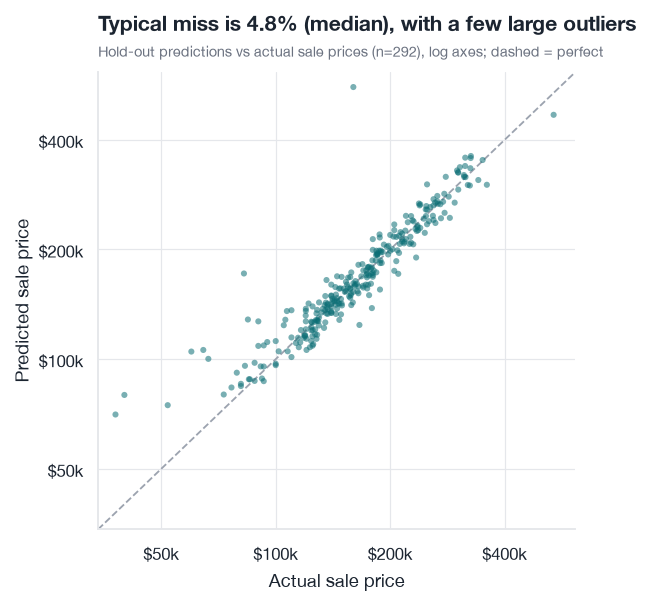

In [4]:
fig = P.plot_pred_vs_actual(y_ho, pred_ho, f"Typical miss is {m['mdape_pct']:.1f}% (median), with a few large outliers",
                            f"Hold-out predictions vs actual sale prices (n={len(y_ho)}), log axes; dashed = perfect")
P.save_fig(fig, "holdout_pred_vs_actual"); plt.show()

## 2 · Where does the model fail?

The hold-out has only 292 houses, too few to slice into segments. For segment analysis we pool **every house, each scored by a model that never saw it**: training rows via their out-of-fold prediction from repeated CV, hold-out rows via the model above. (Segments are defined by *predicted* price, not actual price; slicing by the target manufactures a fake "regression to the mean" bias.)

1,460 out-of-sample predictions, pooled RMSLE 0.1201


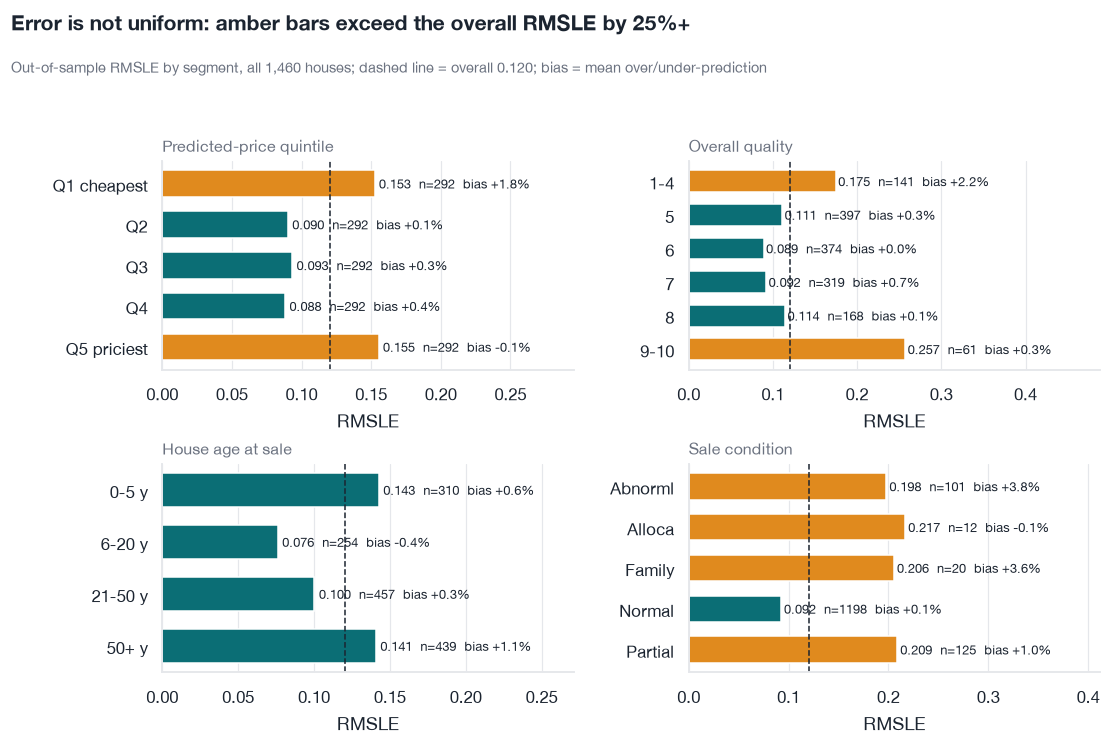

In [5]:
cv = repeated_cv(build(FINAL_MODEL, lgbm_params=params), X_tr, y_tr, name="final")
ev = pd.concat([train.assign(pred=cv.oof, source="train (out-of-fold)"),
                holdout.assign(pred=pred_ho, source="hold-out")], ignore_index=True)
ev["log_err"] = np.log1p(ev.pred) - np.log1p(ev.SalePrice)       # >0 = over-prediction
ev["abs_pct"] = 100 * (ev.pred - ev.SalePrice).abs() / ev.SalePrice
overall = rmsle(ev.SalePrice, ev.pred)
print(f"{len(ev):,} out-of-sample predictions, pooled RMSLE {overall:.4f}")

def seg(by, min_n=1):
    g = ev.groupby(by, observed=True)
    out = pd.DataFrame({"rmsle": g.apply(lambda d: rmsle(d.SalePrice, d.pred), include_groups=False),
                        "bias_%": 100 * (np.exp(g.log_err.mean()) - 1), "n": g.size()})
    return out[out.n >= min_n].reset_index().rename(columns={by if isinstance(by, str) else by[0]: "segment"})

ev["pred_quintile"] = pd.qcut(ev.pred, 5, labels=["Q1 cheapest", "Q2", "Q3", "Q4", "Q5 priciest"])
ev["age_band"] = pd.cut(ev.YrSold - ev.YearBuilt, [-1, 5, 20, 50, 300], labels=["0-5 y", "6-20 y", "21-50 y", "50+ y"])
ev["quality_band"] = pd.cut(ev.OverallQual, [0, 4, 5, 6, 7, 8, 10], labels=["1-4", "5", "6", "7", "8", "9-10"])
panels = {"Predicted-price quintile": seg("pred_quintile"), "Overall quality": seg("quality_band"),
          "House age at sale": seg("age_band"), "Sale condition": seg("SaleCondition", min_n=10)}

fig, axes = plt.subplots(2, 2, figsize=(11, 6.2))
for ax, (title, s) in zip(axes.ravel(), panels.items(), strict=True):
    colours = [P.AMBER if v > 1.25 * overall else P.TEAL for v in s.rmsle]
    ax.barh(s.segment.astype(str), s.rmsle, color=colours, height=0.65)
    for i, (v, n, b) in enumerate(zip(s.rmsle, s.n, s["bias_%"], strict=True)):
        ax.text(v + 0.003, i, f"{v:.3f}  n={n}  bias {b:+.1f}%", va="center", fontsize=8.5)
    ax.axvline(overall, color=P.INK, lw=1, ls="--"); ax.invert_yaxis(); ax.grid(axis="y", visible=False)
    ax.set_xlim(0, max(s.rmsle.max() * 1.9, overall * 2.2)); ax.set_title(title, loc="left", fontsize=10.5, color=P.MUTED, fontweight="normal")
    ax.set_xlabel("RMSLE")
worst_pq = panels["Predicted-price quintile"].sort_values("rmsle").iloc[-1]
P.fig_headline(fig, "Error is not uniform: amber bars exceed the overall RMSLE by 25%+",
               f"Out-of-sample RMSLE by segment, all {len(ev):,} houses; dashed line = overall {overall:.3f}; bias = mean over/under-prediction", y=0.985)
fig.subplots_adjust(top=0.86, hspace=0.45, wspace=0.28)
P.save_fig(fig, "error_by_segment"); plt.show()

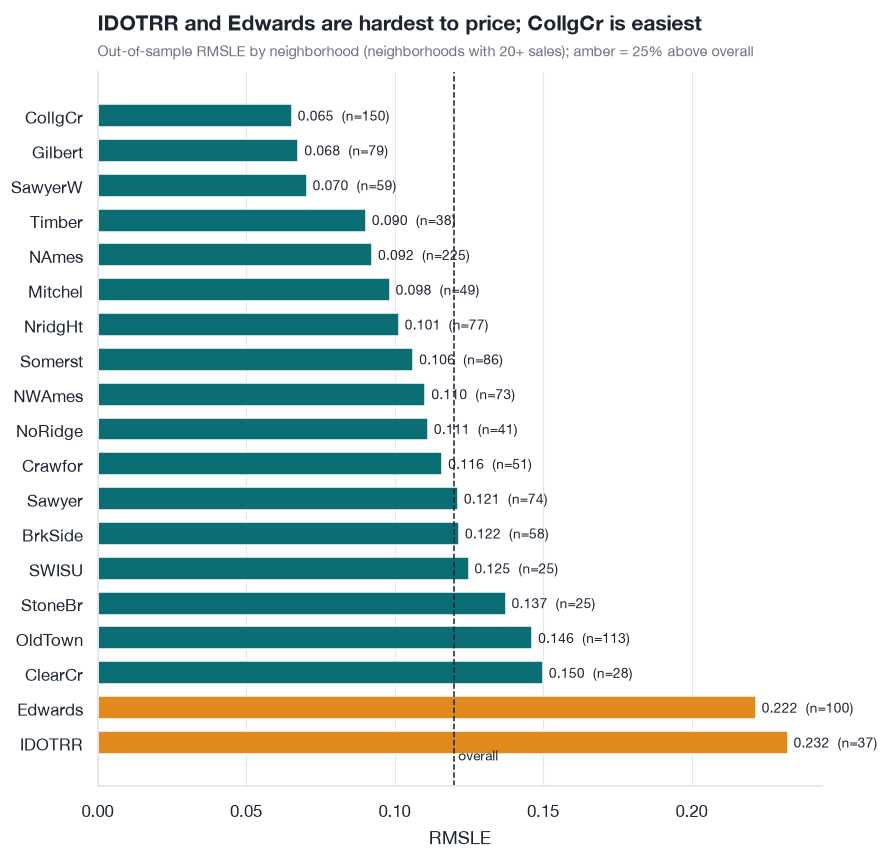

In [6]:
hood = seg("Neighborhood", min_n=20).sort_values("rmsle")
fig = P.plot_segment_errors(hood, f"{hood.iloc[-1].segment} and {hood.iloc[-2].segment} are hardest to price; {hood.iloc[0].segment} is easiest",
                            "Out-of-sample RMSLE by neighborhood (neighborhoods with 20+ sales); amber = 25% above overall", overall=overall)
P.save_fig(fig, "error_by_neighborhood"); plt.show()

**Heavy tails.** RMSLE squares errors, so a few terrible predictions dominate it. How concentrated is the damage?

In [7]:
sq = (ev.log_err ** 2).sort_values(ascending=False)
top1pct = int(np.ceil(0.01 * len(sq)))
share = 100 * sq.head(top1pct).sum() / sq.sum()
display(Markdown(f"The **{top1pct} worst houses (1% of all) account for {share:.0f}% of the total squared log-error**; the worst 5% account for {100 * sq.head(int(0.05 * len(sq))).sum() / sq.sum():.0f}%. Without the worst 1%, pooled RMSLE would be {np.sqrt(sq.iloc[top1pct:].mean()):.4f} instead of {overall:.4f}."))
cols = ["Id", "Neighborhood", "SaleCondition", "OverallQual", "GrLivArea", "YearBuilt", "SalePrice", "pred", "abs_pct"]
worst = ev.loc[sq.head(10).index, cols].round({"pred": 0, "abs_pct": 1}).rename(columns={"pred": "predicted", "abs_pct": "abs err %"})
worst

The **15 worst houses (1% of all) account for 37% of the total squared log-error**; the worst 5% account for 59%. Without the worst 1%, pooled RMSLE would be 0.0961 instead of 0.1201.

,Id,Neighborhood,SaleCondition,OverallQual,GrLivArea,YearBuilt,SalePrice,predicted,abs err %
1316,1299,Edwards,Partial,10,5642,2008,160000,558267.0,248.9
963,524,Edwards,Partial,10,4676,2007,184750,629528.0,240.7
1208,633,NWAmes,Family,7,1411,1977,82500,171841.0,108.3
1432,31,IDOTRR,Normal,4,1317,1920,40000,79756.0,99.4
850,1325,Somerst,Partial,8,1795,2006,147000,292262.0,98.8
650,496,IDOTRR,Abnorml,4,720,1920,34900,67726.0,94.1
149,463,Sawyer,Normal,5,864,1965,62383,120226.0,92.7
1192,969,OldTown,Abnorml,3,968,1910,37900,70487.0,86.0
571,917,IDOTRR,Abnorml,2,480,1949,35311,63763.0,80.6
1282,411,Edwards,Abnorml,5,1276,1958,60000,104914.0,74.9


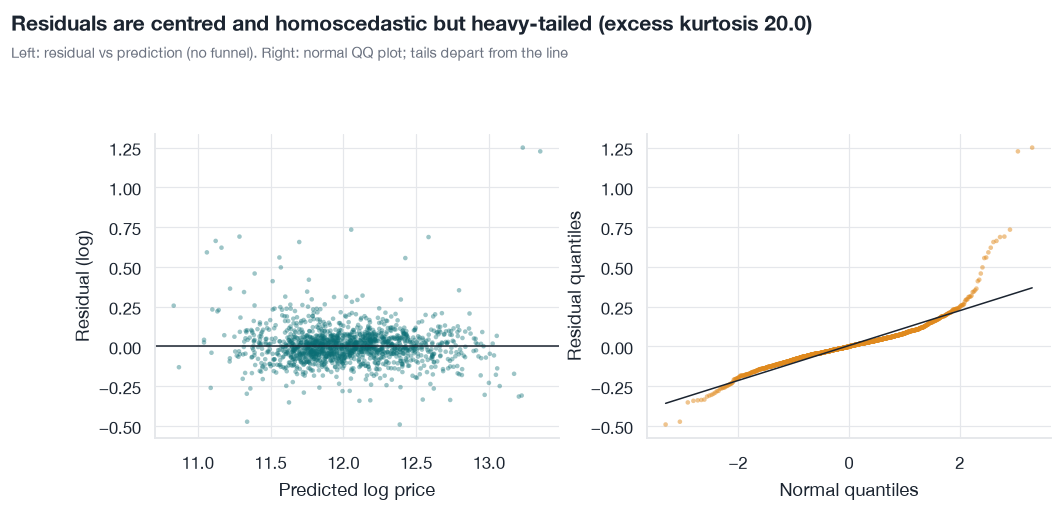

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(10.5, 3.9))
axes[0].scatter(np.log1p(ev.pred), ev.log_err, s=9, alpha=0.4, color=P.TEAL, edgecolor="none")
axes[0].axhline(0, color=P.INK, lw=1); axes[0].set(xlabel="Predicted log price", ylabel="Residual (log)")
stats.probplot(ev.log_err, dist="norm", plot=None)
(osm, osr), (slope, icpt, _) = stats.probplot(ev.log_err, dist="norm")
axes[1].scatter(osm, osr, s=9, alpha=0.5, color=P.AMBER, edgecolor="none"); axes[1].plot(osm, slope * osm + icpt, color=P.INK, lw=1)
axes[1].set(xlabel="Normal quantiles", ylabel="Residual quantiles")
kurt = stats.kurtosis(ev.log_err)
P.fig_headline(fig, f"Residuals are centred and homoscedastic but heavy-tailed (excess kurtosis {kurt:.1f})",
               "Left: residual vs prediction (no funnel). Right: normal QQ plot; tails depart from the line", y=0.99)
fig.subplots_adjust(top=0.82, wspace=0.22)
P.save_fig(fig, "residual_diagnostics"); plt.show()

**What this means.** There is no systematic bias in any segment (mean over/under-prediction stays within a few percent), but error is **U-shaped**: the cheapest and priciest predicted quintiles, the lowest and highest quality grades, and brand-new or very old houses are harder than the middle of the market, where examples are dense. The clearest weakness is **non-normal sales** (abnormal, partial, family, allocation): their RMSLE is roughly double that of normal sales, because the price reflects circumstances not in the 79 columns (a distressed sale, an unfinished build). Residuals are heavy-tailed rather than Gaussian, so intervals should not be "prediction +- 1.96 sd"; section 5 uses a distribution-free method and gives non-normal sales their own margin.

## 3 · Why does it predict what it predicts? — permutation importance

Permutation importance shuffles one raw input column on the hold-out and measures how much RMSLE worsens. It is model-agnostic (it explains the *whole* blend), works on the 79 original columns, and needs no assumption about model internals. Caveat: correlated features (e.g. `GarageCars` / `GarageArea`) share credit, so each one looks less important than the pair together.

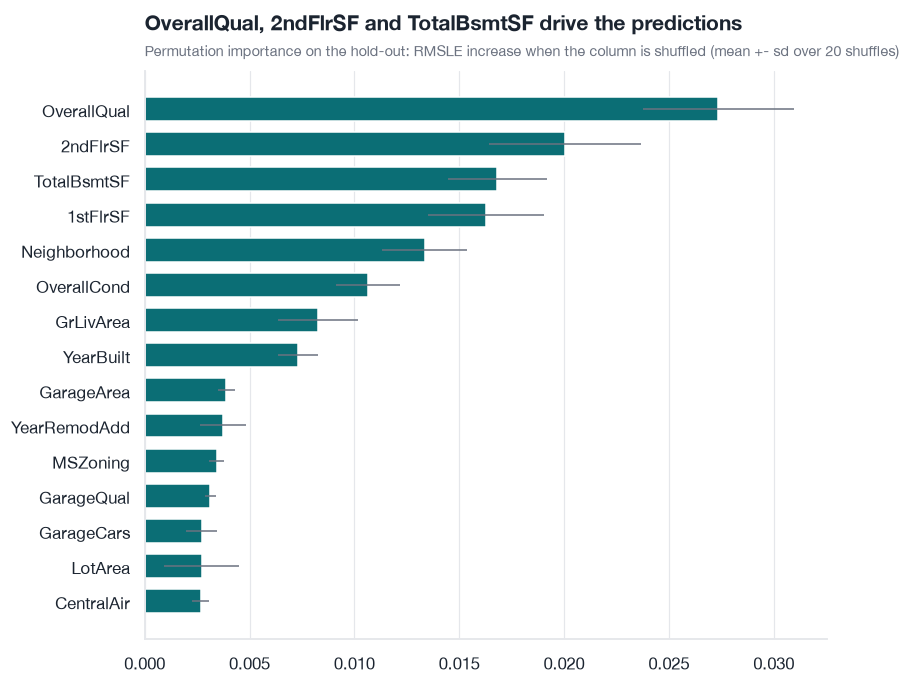

In [9]:
scorer = make_scorer(rmsle, greater_is_better=False)
pi = permutation_importance(point, X_ho, y_ho, scoring=scorer, n_repeats=3 if config.SMOKE else 20,
                            random_state=config.SEED, n_jobs=-1)
perm = pd.DataFrame({"feature": X_ho.columns, "importance": pi.importances_mean, "std": pi.importances_std}).sort_values("importance", ascending=False)
perm.to_csv(config.RESULTS_DIR / "permutation_importance.csv", index=False)
fig = P.plot_importance(perm, f"{perm.iloc[0].feature}, {perm.iloc[1].feature} and {perm.iloc[2].feature} drive the predictions",
                        f"Permutation importance on the hold-out: RMSLE increase when the column is shuffled (mean +- sd over {len(pi.importances[0])} shuffles)")
P.save_fig(fig, "permutation_importance"); plt.show()

## 4 · SHAP: direction and shape of the effects

Permutation importance says *how much*; SHAP says *which way* and *how*. SHAP explains tree models exactly and cheaply, so we explain the **tuned LightGBM component** of the blend (fitted on the training split). Values are in **log-price units**: a SHAP value of +0.10 multiplies the predicted price by e^0.10 = 1.105 (+10.5 %). Features here are the *engineered* ones the trees actually see (e.g. `TotalSF`, `HouseAge`), with categoricals target-encoded to one column each.

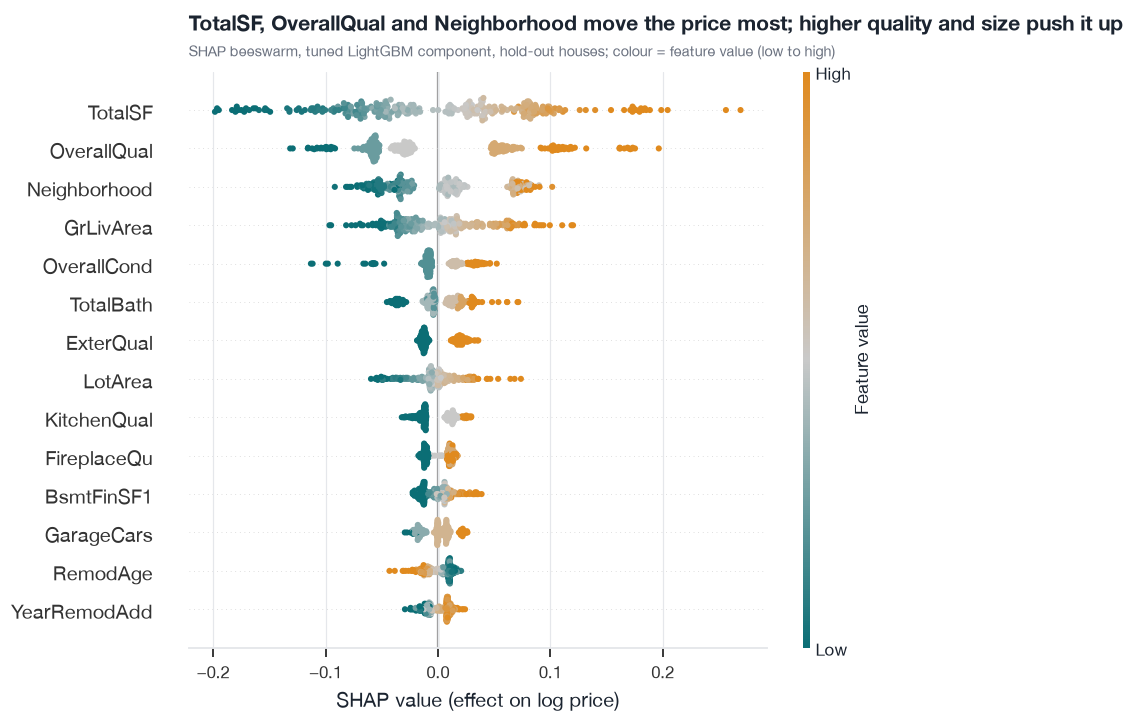

In [10]:
lgbm = log_target(_pipe("tree", _lgbm(params))).fit(X_tr, y_tr)
prep = lgbm.regressor_["prep"]
names = prep["columns"].get_feature_names_out()
Z = pd.DataFrame(prep.transform(X_ho), columns=names, index=X_ho.index)
explainer = shap.TreeExplainer(lgbm.regressor_[-1])
sv = explainer.shap_values(Z)
base = float(np.ravel(explainer.expected_value)[0])
cmap = LinearSegmentedColormap.from_list("tealamber", [P.TEAL, "#c9c9c9", P.AMBER])
plt.figure(figsize=(8.5, 6.2))
shap.summary_plot(sv, Z, max_display=14, cmap=cmap, show=False, plot_size=None)
ax = plt.gca(); ax.set_xlabel("SHAP value (effect on log price)"); ax.grid(axis="y", visible=False)
mean_abs = pd.Series(np.abs(sv).mean(0), index=names).sort_values(ascending=False)
P.headline(ax, f"{mean_abs.index[0]}, {mean_abs.index[1]} and {mean_abs.index[2]} move the price most; higher quality and size push it up",
           "SHAP beeswarm, tuned LightGBM component, hold-out houses; colour = feature value (low to high)")
P.save_fig(plt.gcf(), "shap_summary"); plt.show()

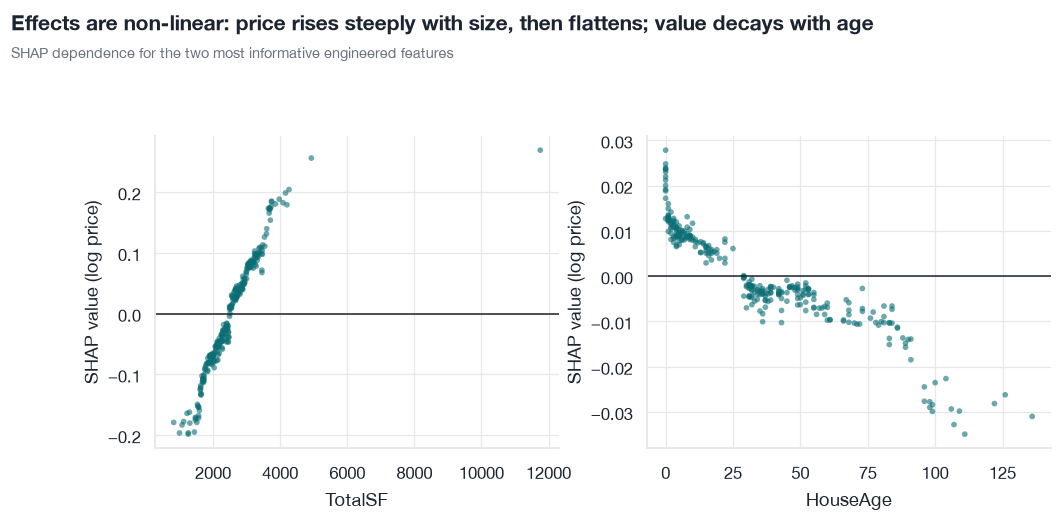

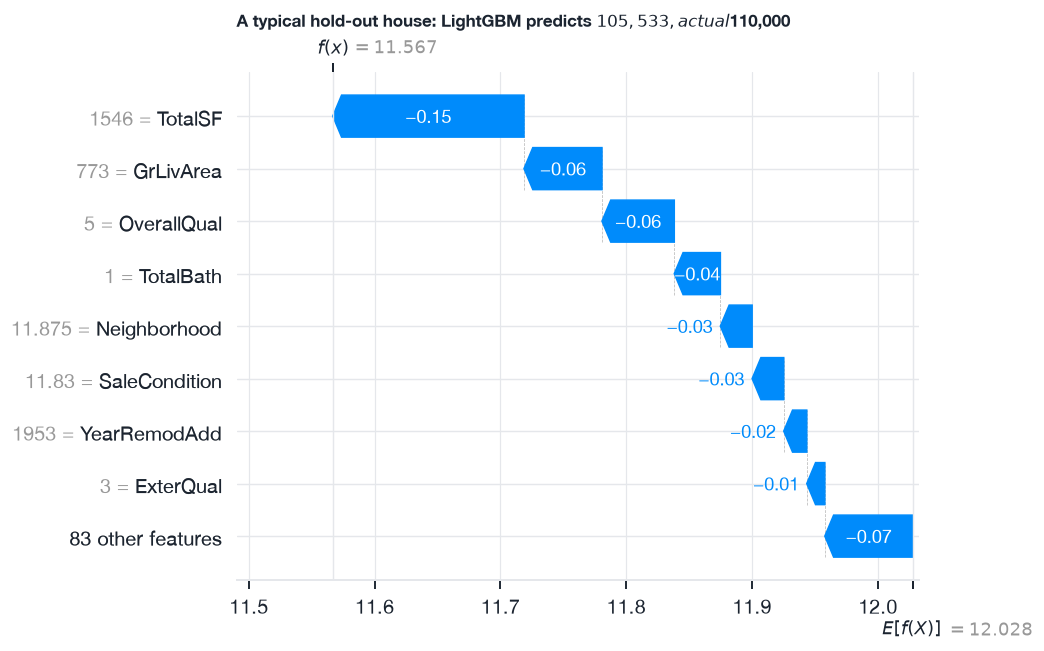

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(10.5, 4.0))
for ax, feat in zip(axes, [mean_abs.index[0], "HouseAge" if "HouseAge" in Z else mean_abs.index[3]], strict=True):
    ax.scatter(Z[feat], sv[:, list(names).index(feat)], s=14, alpha=0.6, color=P.TEAL, edgecolor="none")
    ax.axhline(0, color=P.INK, lw=1); ax.set(xlabel=feat, ylabel="SHAP value (log price)")
P.fig_headline(fig, "Effects are non-linear: price rises steeply with size, then flattens; value decays with age",
               "SHAP dependence for the two most informative engineered features", y=0.99)
fig.subplots_adjust(top=0.82, wspace=0.22)
P.save_fig(fig, "shap_dependence"); plt.show()

# One concrete explanation: the house the model gets most wrong in the hold-out, and a typical one.
i_typ = int(np.argsort(np.abs(pred_ho - y_ho.to_numpy()))[len(y_ho) // 2])
exp = shap.Explanation(values=sv[i_typ], base_values=base, data=Z.iloc[i_typ].to_numpy(), feature_names=list(names))
shap.plots.waterfall(exp, max_display=9, show=False)
plt.gca().set_title(f"A typical hold-out house: LightGBM predicts ${np.expm1(base + sv[i_typ].sum()):,.0f}, actual ${y_ho.iloc[i_typ]:,.0f}",
                    loc="left", fontsize=11, fontweight="bold")
plt.show()

In [12]:
shap_imp = pd.DataFrame({"feature": mean_abs.index, "mean_abs_shap": mean_abs.values})
shared = [f for f in perm.feature if f in set(mean_abs.index)]
rho = stats.spearmanr(perm.set_index("feature").loc[shared, "importance"], mean_abs.reindex(shared)).statistic
top_p, top_s = list(perm.feature[:8]), [f for f in mean_abs.index[:8]]
display(Markdown(f"**Do the two methods agree?** Spearman rank correlation over the {len(shared)} features both can see: **{rho:.2f}**.  \n"
                 f"Top-8 by permutation (blend, raw columns): {', '.join(top_p)}.  \n"
                 f"Top-8 by SHAP (LightGBM, engineered columns): {', '.join(top_s)}.  \n"
                 "Differences are expected: different models, and engineered features such as `TotalSF` absorb the credit of `GrLivArea`, `TotalBsmtSF` and the floor areas."))
shap_imp.to_csv(config.RESULTS_DIR / "shap_importance.csv", index=False)

**Do the two methods agree?** Spearman rank correlation over the 78 features both can see: **0.59**.  
Top-8 by permutation (blend, raw columns): OverallQual, 2ndFlrSF, TotalBsmtSF, 1stFlrSF, Neighborhood, OverallCond, GrLivArea, YearBuilt.  
Top-8 by SHAP (LightGBM, engineered columns): TotalSF, OverallQual, Neighborhood, GrLivArea, OverallCond, TotalBath, ExterQual, LotArea.  
Differences are expected: different models, and engineered features such as `TotalSF` absorb the credit of `GrLivArea`, `TotalBsmtSF` and the floor areas.

## 5 · How sure are we? Prediction intervals with a coverage check

A point estimate hides uncertainty. We compare four interval methods, all targeting **90 % marginal coverage**, and *measure* how often the true price lands inside on the hold-out:

1. **Raw quantile GBM**: LightGBM trained for the 5th and 95th percentiles. Adaptive, no coverage guarantee.
2. **CQR** (conformalised quantile regression): the same band widened by the margin that makes it cover 90 % of *out-of-fold* training houses.
3. **Constant-width conformal**: blend prediction times/divided by one factor from out-of-fold log residuals.
4. **Mondrian conformal** (shipped): like 3, but with a separate factor for *normal* and *non-normal* sales, because section 2 showed non-normal sales are far harder to price.

Coverage is estimated from 292 houses, so it carries its own error bar (Wilson 95 % interval). Calibration never touches the hold-out, but note that choosing which method to ship after seeing hold-out results is a mild form of selection; the coverage of any single method is still a fair estimate because calibration is independent of it.

In [13]:
y_arr = y_ho.to_numpy()
cqr = ConformalQuantileInterval(INTERVAL_ALPHA, params).fit(X_tr, y_tr)
lo_raw, hi_raw = cqr.predict_interval(X_ho, calibrated=False)
lo_cqr, hi_cqr = cqr.predict_interval(X_ho)
q_const = abs_residual_interval(np.log1p(y_tr.to_numpy()), np.log1p(cv.oof), INTERVAL_ALPHA)
lo_c, hi_c = np.expm1(np.log1p(pred_ho) - q_const), np.expm1(np.log1p(pred_ho) + q_const)
lo_m, hi_m = interval.predict_interval(X_ho, pred_ho)      # shipped Mondrian interval
methods = {"Raw quantile GBM (5%-95%)": (lo_raw, hi_raw), "CQR": (lo_cqr, hi_cqr),
           "Constant-width conformal": (lo_c, hi_c), "Mondrian conformal (shipped)": (lo_m, hi_m)}
normal = (holdout.SaleCondition == "Normal").to_numpy()
rows = []
for name, (a, b) in methods.items():
    r = coverage_report(y_arr, a, b)
    ins = (y_arr >= a) & (y_arr <= b)
    wl, wh = wilson_interval(int(ins.sum()), len(y_arr))
    rows.append({"method": name, "coverage": r["coverage"], "95% CI of coverage": f"[{wl:.3f}, {wh:.3f}]",
                 "coverage normal sales": ins[normal].mean(), "coverage non-normal": ins[~normal].mean(),
                 "median width (% of price)": 100 * r["median_rel_width"], "mean width ($)": r["mean_width_usd"]})
cov = pd.DataFrame(rows)
cov.to_csv(config.RESULTS_DIR / "interval_coverage.csv", index=False)
display(Markdown(f"Calibrated log-margins of the shipped interval: {({k: round(v, 3) for k, v in interval.q_.items()})}; pooled {interval.q_pooled_:.3f}. Hold-out sizes: {int(normal.sum())} normal, {int((~normal).sum())} non-normal sales."))
cov.round(3)

Calibrated log-margins of the shipped interval: {'non-normal': 0.255, 'normal': 0.151}; pooled 0.171. Hold-out sizes: 248 normal, 44 non-normal sales.

,method,coverage,95% CI of coverage,coverage normal sales,coverage non-normal,median width (% of price),mean width ($)
0,Raw quantile GBM (5%-95%),0.771,"[0.719, 0.815]",0.786,0.682,30.152,61041.676
1,CQR,0.918,"[0.881, 0.944]",0.940,0.795,45.382,87224.617
2,Constant-width conformal,0.921,"[0.885, 0.947]",0.952,0.750,33.981,60373.677
3,Mondrian conformal (shipped),0.908,"[0.869, 0.936]",0.919,0.841,31.030,60022.836


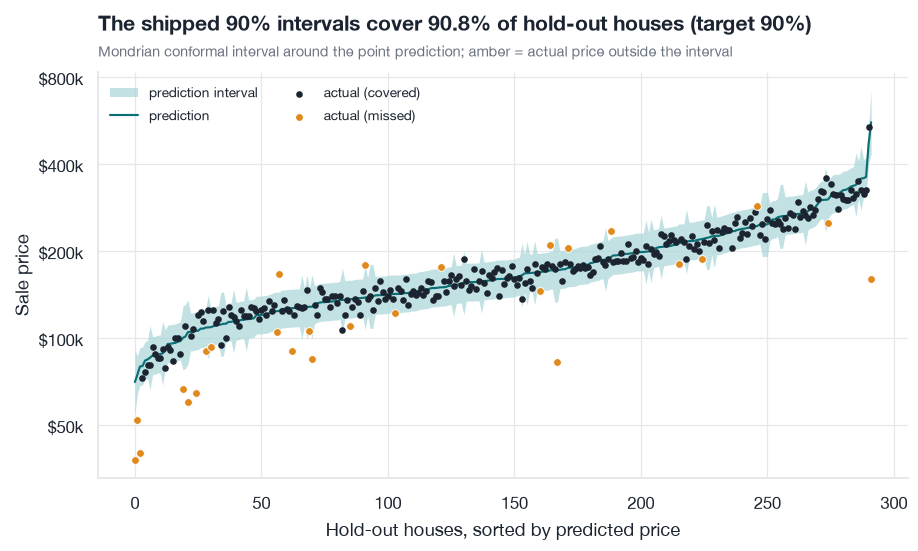

In [14]:
fig = P.plot_intervals(y_arr, lo_m, hi_m, pred_ho,
                       f"The shipped 90% intervals cover {100 * cov.iloc[3]['coverage']:.1f}% of hold-out houses (target 90%)",
                       "Mondrian conformal interval around the point prediction; amber = actual price outside the interval")
P.save_fig(fig, "prediction_intervals"); plt.show()

In [15]:
# Conditional behaviour of the shipped interval: marginal coverage can hide weak segments.
h = holdout.assign(pred=pred_ho, lo=lo_m, hi=hi_m)
h["covered"] = (h.SalePrice >= h.lo) & (h.SalePrice <= h.hi)
h["rel_width_%"] = 100 * (h.hi - h.lo) / h.SalePrice
h["pred_tercile"] = pd.qcut(h.pred, 3, labels=["cheapest third", "middle third", "priciest third"])
h["sale"] = np.where(h.SaleCondition == "Normal", "Normal sale", "Non-normal sale")
by = lambda col: h.groupby(col, observed=True).agg(n=("covered", "size"), coverage=("covered", "mean"), median_width_pct=("rel_width_%", "median")).round(3)
display(pd.concat({"by predicted price": by("pred_tercile"), "by sale type": by("sale")}))
miss = h[~h.covered]
display(Markdown(f"{len(miss)} of {len(h)} hold-out houses fall outside their interval: {int((miss.SalePrice > miss.hi).sum())} above, {int((miss.SalePrice < miss.lo).sum())} below."))

n  coverage  median_width_pct
by predicted price cheapest third    98     0.847            31.010
                   middle third      97     0.928            30.656
                   priciest third    97     0.948            31.326
by sale type       Non-normal sale   44     0.841            51.742
                   Normal sale      248     0.919            30.459

27 of 292 hold-out houses fall outside their interval: 7 above, 20 below.

**Takeaways on uncertainty.** Compare the table rows honestly: the raw quantile band under-covers; the conformal methods repair the *marginal* coverage. CQR did not buy sharper intervals than the far simpler constant-width conformal method on this data, which is why the shipped method is residual-based, and the Mondrian variant targets the one weakness diagnosed in section 2 (non-normal sales). Guarantees are marginal (and per sale type for Mondrian), not per neighborhood or price band; segments of ~100 houses give noisy estimates, so small deviations from 90 % in the conditional table are not evidence of failure either way.

## 6 · Limitations (read before using this model for anything real)

* **Small, old, local data.** 1,460 sales from one Iowa college town in 2006–2010 (a housing crash). Nothing here transfers to another market or to today's prices without re-training on local, recent data. The model has never seen a sale outside 2006–2010; the inference schema accepts later years but the predictions would be extrapolation.
* **Random split, not time split.** Hold-out houses are interleaved in time with training houses. A deployment predicting *future* sales would face drift, and honest performance would be worse than reported here.
* **Some features exist only after the sale.** `SaleType` and `SaleCondition` describe the transaction (foreclosure, new construction not yet complete). A listing-price tool would not know them; dropping them would cost accuracy and is the right setup for that use case.
* **Heavy-tailed errors.** A handful of unusual sales dominate the squared error (section 2). Typical error is much smaller than RMSLE suggests; worst-case error is much larger.
* **Selection optimism.** The tuned model's CV score is slightly optimistic (notebook 02 measures the gap). The hold-out is unbiased but, with 292 rows, noisy: see the bootstrap CI. Only LightGBM was tuned; other models use sensible defaults, so the comparison slightly favours it.
* **Conformal guarantees are marginal and approximate.** They assume exchangeability, use out-of-fold residuals with a refit model, and say nothing about any particular neighborhood. Coverage was measured, not assumed, but on a small hold-out.
* **Features are proxies.** Neighborhood is a strong predictor and can encode socio-economic patterns; do not use a model like this for decisions that affect people (lending, taxation, insurance) without a fairness review.
* **Explanations are associations**, not causal effects: renovating a kitchen will not raise your price by the SHAP value of `KitchenQual`.

In [16]:
elapsed = time.perf_counter() - T0
summary = {"model": FINAL_MODEL + " (tuned LightGBM params)", "n_train": len(train), "n_holdout": len(holdout), **{k: v for k, v in m.items()},
           "interval_nominal": 1 - INTERVAL_ALPHA, "interval_coverage_holdout": {r["method"]: r["coverage"] for r in rows}, "holdout_rmsle_excluding_flagged_outlier": m_ex["rmsle"],
           "pooled_oos_rmsle": overall, "worst_1pct_share_of_sq_error_pct": share, "spearman_perm_vs_shap": rho, "fit_seconds": res["fit_seconds"]}
(config.RESULTS_DIR / "holdout_metrics.json").write_text(json.dumps(summary, indent=2, default=float))

rt_path = config.RESULTS_DIR / "runtimes.json"
rt = json.loads(rt_path.read_text()) if rt_path.exists() else {}
rt["03_error_analysis_seconds"] = round(elapsed, 1)
rt_path.write_text(json.dumps(rt, indent=2))
print(f"notebook runtime: {elapsed:.0f}s")

notebook runtime: 42s
